# Exploratory Data Analysis (EDA) - NYC Short-Term Rental Prices

This notebook performs exploratory data analysis on the NYC short-term rental listings dataset.
The objectives of this EDA are:
1. Load the raw sample data tracked in Weights & Biases (`sample.csv:latest`).
2. Explore column distributions, missing values, and potential outliers.
3. Define cleaning rules for the upstream ML pipeline:
   - Price range filtering ($10 to $350 inclusive).
   - Date format standardization for `last_review`.
   - Explicit strategy for missing values (retained for inference pipeline imputation).
4. Verify data distributions post-cleaning.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import wandb

# Set plot style
plt.style.use('seaborn-v0_8' if 'seaborn-v0_8' in plt.style.available else 'default')
%matplotlib inline

## 1. Fetching Data from Weights & Biases

We initialize a W&B run in the `nyc_airbnb` project under the `eda` job type and download the latest raw dataset artifact (`sample.csv:latest`). Tracking artifacts ensures reproducibility and lineage throughout the pipeline.

In [2]:
# Initialize W&B run with code saving enabled
run = wandb.init(project="nyc_airbnb", job_type="eda", save_code=True)

# Fetch latest raw data artifact
artifact = run.use_artifact("sample.csv:latest")
data_path = artifact.file()
df = pd.read_csv(data_path)
print(f"Loaded dataset shape: {df.shape}")
df.head()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from ~/.netrc.


wandb: Currently logged in as: kenseiamit (kenseiamit) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: setting up run x03xzjyt


wandb: Tracking run with wandb version 0.30.0


wandb: Run data is saved locally in ./
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run lemon-firebrand-16


wandb: ⭐️ View project at https://wandb.ai/kenseiamit/nyc_airbnb


wandb: 🚀 View run at https://wandb.ai/kenseiamit/nyc_airbnb/runs/x03xzjyt


Loaded dataset shape: (20000, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,9138664,Private Lg Room 15 min to Manhattan,47594947,Iris,Queens,Sunnyside,40.74271,-73.92493,Private room,74,2,6,2019-05-26,0.13,1,5
1,31444015,TIME SQUARE CHARMING ONE BED IN HELL'S KITCHEN...,8523790,Johlex,Manhattan,Hell's Kitchen,40.76682,-73.98878,Entire home/apt,170,3,0,NaN,NaN,1,188
2,8741020,Voted #1 Location Quintessential 1BR W Village...,45854238,John,Manhattan,West Village,40.73631,-74.00611,Entire home/apt,245,3,51,2018-09-19,1.12,1,0
3,34602077,Spacious 1 bedroom apartment 15min from Manhattan,261055465,Regan,Queens,Astoria,40.76424,-73.92351,Entire home/apt,125,3,1,2019-05-24,0.65,1,13
4,23203149,Big beautiful bedroom in huge Bushwick apartment,143460,Megan,Brooklyn,Bushwick,40.69839,-73.92044,Private room,65,2,8,2019-06-23,0.52,2,8


## 2. Dataset Overview & Schema Inspection

Let's examine column names, data types, and non-null counts to understand the dataset structure.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              20000 non-null  int64  
 1   name                            19993 non-null  object 
 2   host_id                         20000 non-null  int64  
 3   host_name                       19992 non-null  object 
 4   neighbourhood_group             20000 non-null  object 
 5   neighbourhood                   20000 non-null  object 
 6   latitude                        20000 non-null  float64
 7   longitude                       20000 non-null  float64
 8   room_type                       20000 non-null  object 
 9   price                           20000 non-null  int64  
 10  minimum_nights                  20000 non-null  int64  
 11  number_of_reviews               20000 non-null  int64  
 12  last_review                     

## 3. Missing Value Analysis

We check for missing values across all features.

In [4]:
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({"Missing Count": missing_counts, "Percentage (%)": missing_percent.round(2)})
missing_df[missing_df["Missing Count"] > 0]

,Missing Count,Percentage (%)
name,7,0.03
host_name,8,0.04
last_review,4123,20.62
reviews_per_month,4123,20.62


### Decision on Missing Values:
> **Important Note:**
> Missing values are identified in columns such as `name`, `host_name`, `last_review`, and `reviews_per_month`.
> **We do NOT impute missing values during this EDA or in the basic cleaning step.**
> In a production ML pipeline, all feature imputation (e.g., handling missing reviews, imputation of categorical/numerical columns) must be handled dynamically inside the scikit-learn inference pipeline to prevent data leakage and ensure seamless handling of unobserved data during inference.

## 4. Price Distribution and Outlier Analysis

The target variable is `price` (nightly rental price in USD). Let's inspect its summary statistics and identify anomalies.

In [5]:
print(df["price"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

count    20000.000000
mean       153.269050
std        243.325609
min          0.000000
1%          30.000000
5%          40.000000
25%         69.000000
50%        105.000000
75%        175.000000
95%        350.000000
99%        800.000000
max      10000.000000
Name: price, dtype: float64


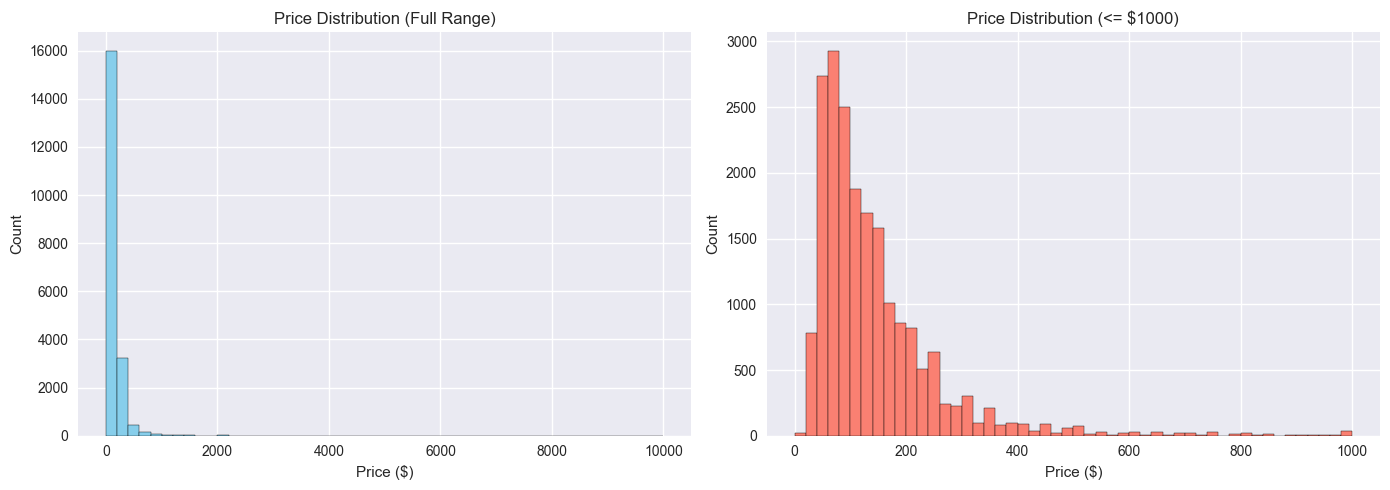

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df["price"], bins=50, color="skyblue", edgecolor="black")
axes[0].set_title("Price Distribution (Full Range)")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Count")

axes[1].hist(df[df["price"] <= 1000]["price"], bins=50, color="salmon", edgecolor="black")
axes[1].set_title("Price Distribution (<= $1000)")
axes[1].set_xlabel("Price ($)")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

### Cleaning Decision: Price Boundaries
The distribution shows extreme values:
- Several listings have a price of $0 (erroneous listings).
- Luxury or anomalous outliers range up to $10,000, skewing the distribution.
- Following project requirements, we filter prices to the accepted nightly range: **$10 <= price <= $350 (inclusive)**.

In [7]:
# Clean price outliers
min_price, max_price = 10, 350
idx_price = df["price"].between(min_price, max_price)
removed_count = len(df) - idx_price.sum()
print(f"Rows outside [${min_price}, ${max_price}]: {removed_count} ({removed_count / len(df):.2%})")

df_clean = df[idx_price].copy()
print(f"Cleaned dataset shape: {df_clean.shape}")

Rows outside [$10, $350]: 999 (5.00%)
Cleaned dataset shape: (19001, 16)


## 5. Date Feature Inspection: `last_review`

`last_review` is currently stored as an `object` (string). To perform feature engineering (such as calculating the days elapsed since the last review), it must be converted to datetime.

In [8]:
# Convert last_review to datetime
df_clean["last_review"] = pd.to_datetime(df_clean["last_review"])
print(f"last_review dtype: {df_clean['last_review'].dtype}")
df_clean["last_review"].describe()

last_review dtype: datetime64[ns]


count                            15243
mean     2018-10-01 08:24:05.384766720
min                2011-05-12 00:00:00
25%                2018-06-29 12:00:00
50%                2019-05-19 00:00:00
75%                2019-06-23 00:00:00
max                2019-07-08 00:00:00
Name: last_review, dtype: object

## 6. Post-Cleaning Inspection & Feature Relationships

Let's review the cleaned dataset distributions across neighborhoods and room types.

/var/folders/85/kh71t69d27z3l02d21vvrst40000gp/T/ipykernel_57657/4015426304.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="neighbourhood_group", y="price", ax=axes[1], palette="Set2")


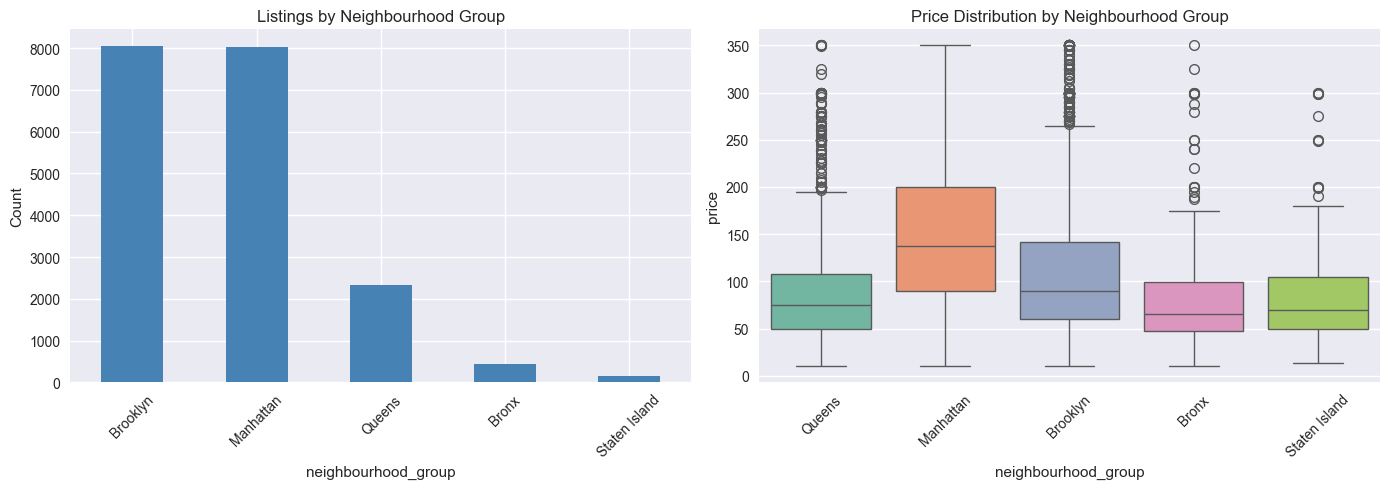

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_clean["neighbourhood_group"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Listings by Neighbourhood Group")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=df_clean, x="neighbourhood_group", y="price", ax=axes[1], palette="Set2")
axes[1].set_title("Price Distribution by Neighbourhood Group")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

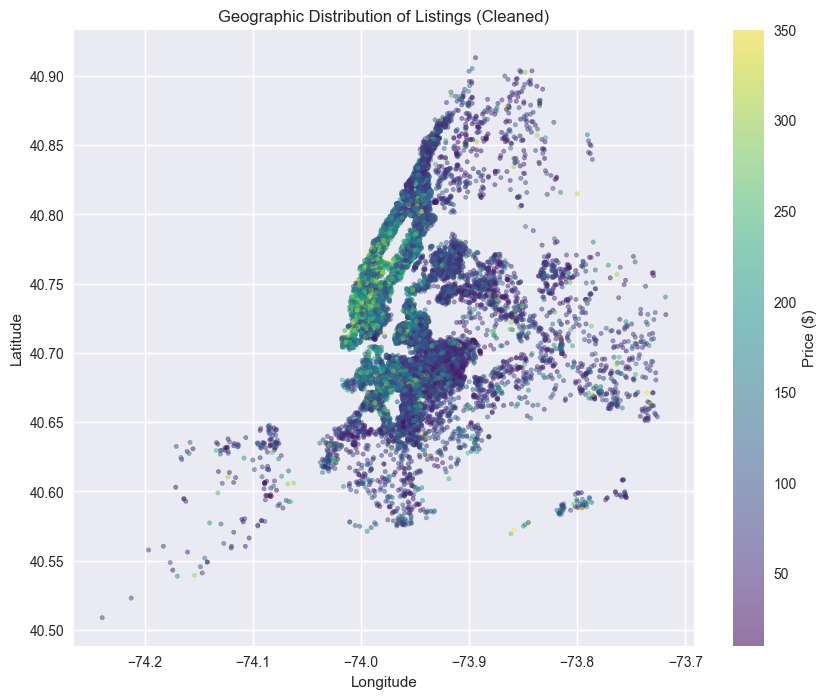

In [10]:
# Spatial distribution of listings
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    df_clean["longitude"],
    df_clean["latitude"],
    c=df_clean["price"],
    cmap="viridis",
    alpha=0.5,
    s=10
)
plt.colorbar(scatter, label="Price ($)")
plt.title("Geographic Distribution of Listings (Cleaned)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## 7. Finish W&B Run

Conclude the EDA session and record the run completion in Weights & Biases.

In [11]:
run.finish()
print("EDA run completed and synced to W&B.")

wandb: updating run metadata


wandb: uploading diff_1327a5ae1fc4dbc0d1f884a2c8a42767bfdf47a2.patch; uploading wandb-metadata.json; uploading requirements.txt; uploading wandb-summary.json; uploading config.yaml (+ 1 more)


wandb: 🚀 View run lemon-firebrand-16 at: https://wandb.ai/kenseiamit/nyc_airbnb/runs/x03xzjyt
wandb: ⭐️ View project at: https://wandb.ai/kenseiamit/nyc_airbnb
wandb: Synced 6 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261015_211413-x03xzjyt/logs


EDA run completed and synced to W&B.
